In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Reprodutibilidade dos experimentos
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

# Seleção do dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Memória da GPU:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.15.0+cu134
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4070
Memória da GPU: 11.99 GB


In [5]:
from torchvision import datasets

# Baixar e carregar a CIFAR-10
train_dataset_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

# Nomes das classes
class_names = [
    "avião", "automóvel", "pássaro", "gato", "veado",
    "cachorro", "sapo", "cavalo", "navio", "caminhão"
]

print("Imagens de treinamento:", len(train_dataset_full))
print("Imagens de teste:", len(test_dataset))
print("Classes:", class_names)

100%|██████████| 170M/170M [14:07<00:00, 201kB/s]  


Imagens de treinamento: 50000
Imagens de teste: 10000
Classes: ['avião', 'automóvel', 'pássaro', 'gato', 'veado', 'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']


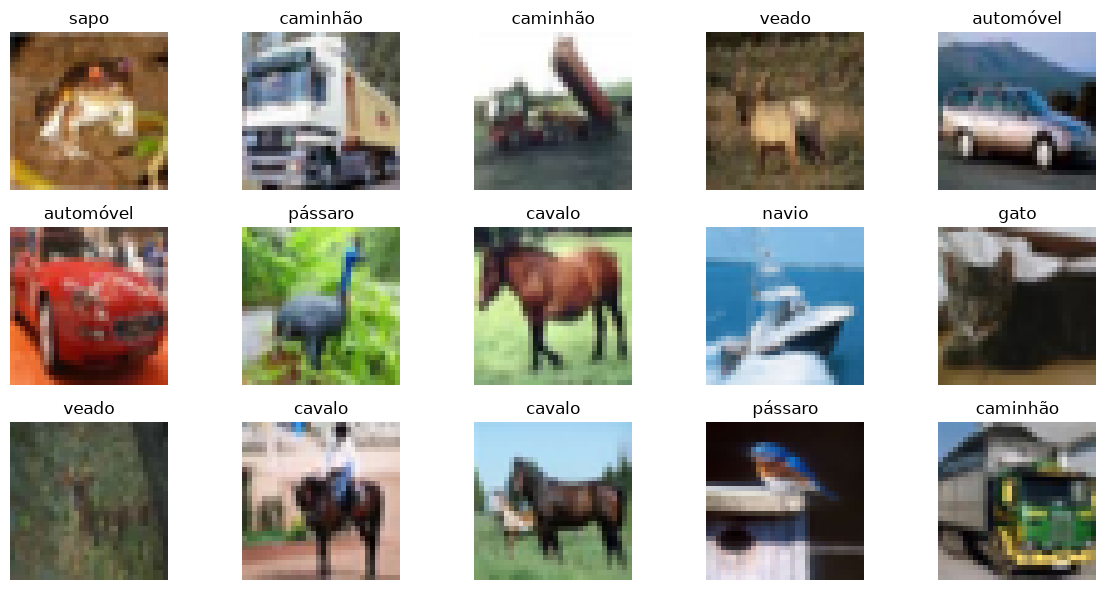

In [6]:
# Visualizar 15 imagens da CIFAR-10
plt.figure(figsize=(12, 6))

for i in range(15):
    imagem, classe = train_dataset_full[i]

    plt.subplot(3, 5, i + 1)
    plt.imshow(imagem)
    plt.title(class_names[classe])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Normalização baseada nas estatísticas da CIFAR-10
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Transformações para treinamento
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Transformações para validação e teste
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Criar conjuntos com transformações diferentes
train_full_aug = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

train_full_normal = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=test_transform
)

# Separação estratificada: 90% treino e 10% validação
indices = np.arange(len(train_full_aug))
labels = np.array(train_full_aug.targets)

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.1,
    random_state=SEED,
    stratify=labels
)

train_dataset = Subset(train_full_aug, train_idx)
val_dataset = Subset(train_full_normal, val_idx)

# DataLoaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Treinamento:", len(train_dataset))
print("Validação:", len(val_dataset))
print("Teste:", len(test_dataset))

Treinamento: 45000
Validação: 5000
Teste: 10000


In [8]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(32 * 32 * 3, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


mlp_model = MLP().to(device)

print(mlp_model)

print(
    "Parâmetros treináveis:",
    sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=2048, bias=True)
    (2): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=2048, out_features=1024, bias=True)
    (6): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=1024, out_features=512, bias=True)
    (10): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=512, out_features=256, bias=True)
    (14): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (15): ReLU()
    (16): Dropout(p=0.2, inplace=False)
    (17): Linear(in_features=256, out_feat

In [10]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Bloco 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            # Bloco 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            # Bloco 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            # Bloco 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


cnn_model = CNN().to(device)

print(cnn_model)

print(
    "Parâmetros treináveis:",
    sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode

In [11]:
import copy
import time
import pandas as pd

from pathlib import Path

# Configurações do treinamento
EPOCHS = 100
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PATIENCE = 12

# Pasta para salvar os modelos
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)


def train_model(model, train_loader, val_loader, model_name):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    history = {
        "loss": [],
        "accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    start_time = time.time()

    for epoch in range(EPOCHS):

        # TREINAMENTO
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_accuracy = train_correct / train_total

        # VALIDAÇÃO
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.inference_mode():
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_accuracy = val_correct / val_total

        # Registrar histórico
        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # Ajustar taxa de aprendizado
        scheduler.step(val_loss)

        # Salvar o melhor modelo
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0

            torch.save(
                best_weights,
                MODELS_DIR / f"{model_name}_best.pth"
            )
        else:
            patience_counter += 1

        print(
            f"{model_name} | Época {epoch+1:03d}/{EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Acc: {train_accuracy*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy*100:.2f}% | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}",
            flush=True
        )

        # Early Stopping
        if patience_counter >= PATIENCE:
            print(f"\nEarly Stopping na época {epoch+1}")
            break

    # Restaurar melhores pesos
    model.load_state_dict(best_weights)
    model.eval()

    elapsed = (time.time() - start_time) / 60

    print(f"\n{model_name} finalizado!")
    print(f"Melhor Val Loss: {best_val_loss:.4f}")
    print(f"Tempo total: {elapsed:.2f} minutos\n")

    # Salvar histórico
    pd.DataFrame(history).to_csv(
        MODELS_DIR / f"{model_name}_history.csv",
        index=False
    )

    return history


# Treinar MLP
print("========== TREINANDO MLP ==========")

history_mlp = train_model(
    mlp_model,
    train_loader,
    val_loader,
    "mlp"
)

# Treinar CNN
print("========== TREINANDO CNN ==========")

history_cnn = train_model(
    cnn_model,
    train_loader,
    val_loader,
    "cnn"
)


========== TREINANDO MLP ==========
mlp | Época 001/100 | Loss: 1.8734 | Acc: 31.50% | Val Loss: 1.6520 | Val Acc: 40.08% | LR: 0.001000
mlp | Época 002/100 | Loss: 1.7032 | Acc: 38.42% | Val Loss: 1.5471 | Val Acc: 44.98% | LR: 0.001000
mlp | Época 003/100 | Loss: 1.6343 | Acc: 40.93% | Val Loss: 1.4779 | Val Acc: 46.30% | LR: 0.001000
mlp | Época 004/100 | Loss: 1.5854 | Acc: 42.76% | Val Loss: 1.4502 | Val Acc: 47.08% | LR: 0.001000
mlp | Época 005/100 | Loss: 1.5509 | Acc: 43.98% | Val Loss: 1.4408 | Val Acc: 47.30% | LR: 0.001000
mlp | Época 006/100 | Loss: 1.5294 | Acc: 44.91% | Val Loss: 1.3936 | Val Acc: 50.42% | LR: 0.001000
mlp | Época 007/100 | Loss: 1.5100 | Acc: 45.53% | Val Loss: 1.3849 | Val Acc: 50.14% | LR: 0.001000
mlp | Época 008/100 | Loss: 1.4878 | Acc: 46.46% | Val Loss: 1.3650 | Val Acc: 51.10% | LR: 0.001000
mlp | Época 009/100 | Loss: 1.4682 | Acc: 47.09% | Val Loss: 1.3462 | Val Acc: 51.32% | LR: 0.001000
mlp | Época 010/100 | Loss: 1.4529 | Acc: 47.81% | Val 

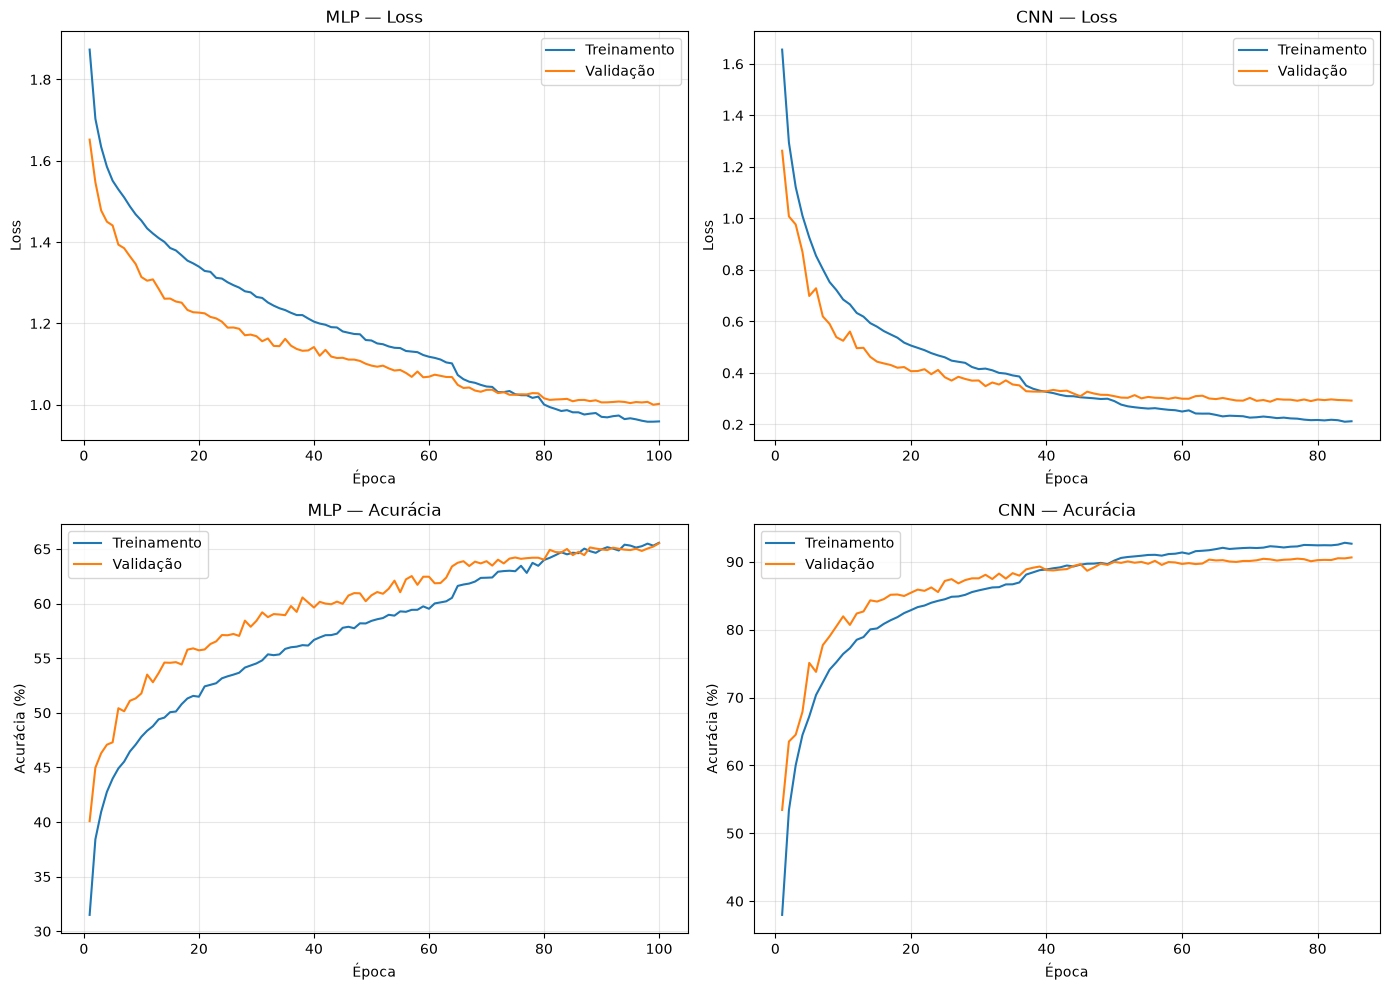

In [12]:
# Históricos dos modelos
historicos = {
    "MLP": history_mlp,
    "CNN": history_cnn
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for coluna, (nome, history) in enumerate(historicos.items()):

    epocas = range(1, len(history["loss"]) + 1)

    # Curvas de perda
    axes[0, coluna].plot(
        epocas, history["loss"], label="Treinamento"
    )
    axes[0, coluna].plot(
        epocas, history["val_loss"], label="Validação"
    )

    axes[0, coluna].set_title(f"{nome} — Loss")
    axes[0, coluna].set_xlabel("Época")
    axes[0, coluna].set_ylabel("Loss")
    axes[0, coluna].legend()
    axes[0, coluna].grid(alpha=0.3)

    # Curvas de acurácia
    axes[1, coluna].plot(
        epocas,
        np.array(history["accuracy"]) * 100,
        label="Treinamento"
    )
    axes[1, coluna].plot(
        epocas,
        np.array(history["val_accuracy"]) * 100,
        label="Validação"
    )

    axes[1, coluna].set_title(f"{nome} — Acurácia")
    axes[1, coluna].set_xlabel("Época")
    axes[1, coluna].set_ylabel("Acurácia (%)")
    axes[1, coluna].legend()
    axes[1, coluna].grid(alpha=0.3)

plt.tight_layout()
plt.show()


MLP — Acurácia no teste: 64.86%

Relatório de classificação:
              precision    recall  f1-score   support

       avião       0.71      0.69      0.70      1000
   automóvel       0.76      0.74      0.75      1000
     pássaro       0.54      0.54      0.54      1000
        gato       0.48      0.46      0.47      1000
       veado       0.60      0.53      0.56      1000
    cachorro       0.58      0.55      0.56      1000
        sapo       0.65      0.78      0.71      1000
      cavalo       0.73      0.73      0.73      1000
       navio       0.76      0.76      0.76      1000
    caminhão       0.67      0.72      0.69      1000

    accuracy                           0.65     10000
   macro avg       0.65      0.65      0.65     10000
weighted avg       0.65      0.65      0.65     10000



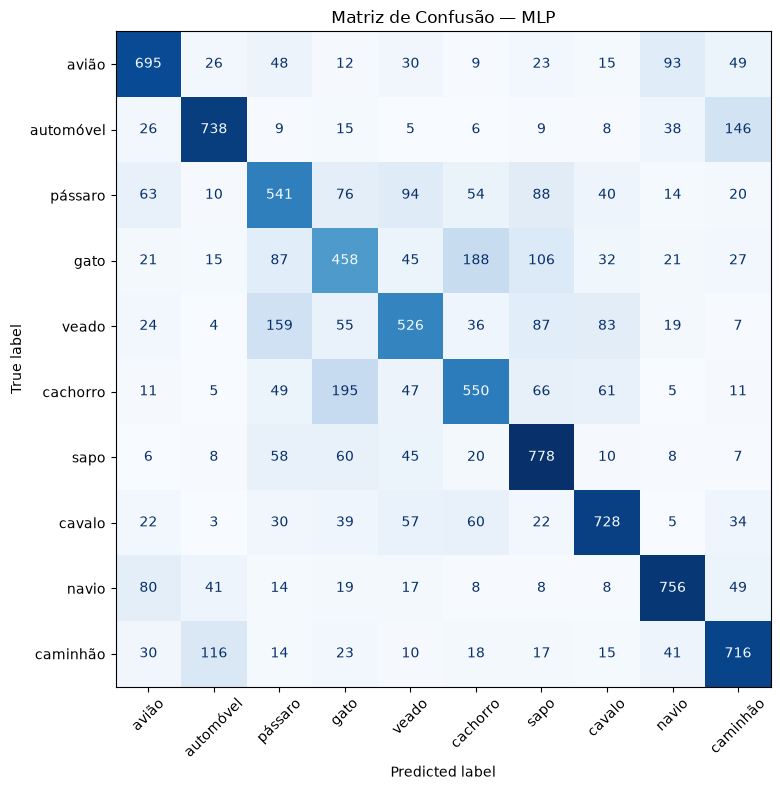


CNN — Acurácia no teste: 90.50%

Relatório de classificação:
              precision    recall  f1-score   support

       avião       0.92      0.91      0.91      1000
   automóvel       0.96      0.95      0.96      1000
     pássaro       0.88      0.87      0.88      1000
        gato       0.85      0.75      0.80      1000
       veado       0.88      0.93      0.91      1000
    cachorro       0.82      0.86      0.84      1000
        sapo       0.92      0.93      0.93      1000
      cavalo       0.94      0.93      0.94      1000
       navio       0.95      0.95      0.95      1000
    caminhão       0.93      0.96      0.94      1000

    accuracy                           0.91     10000
   macro avg       0.90      0.91      0.90     10000
weighted avg       0.90      0.91      0.90     10000



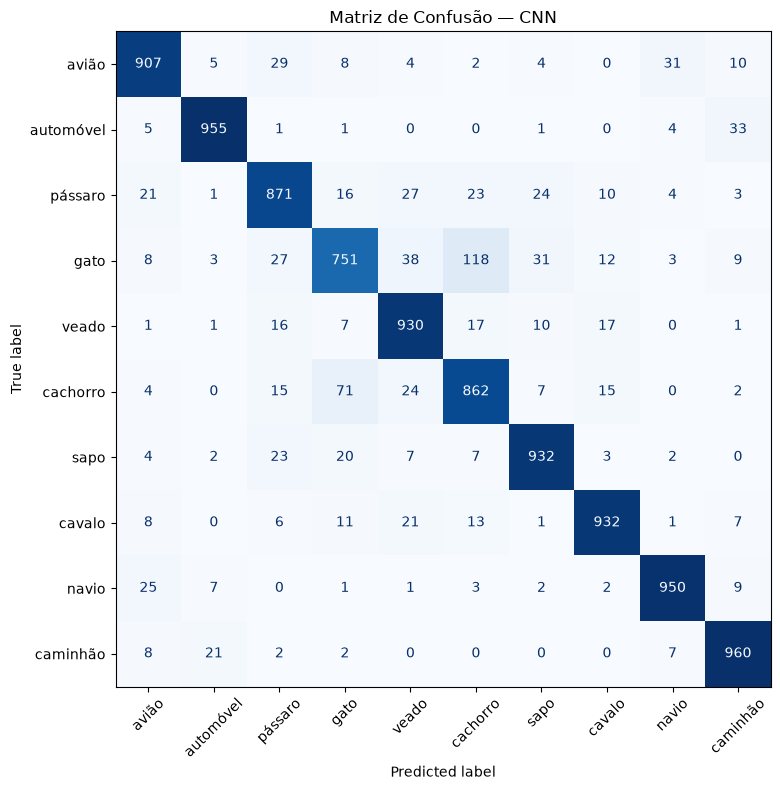


========== COMPARAÇÃO ==========
MLP original: 45.17%
MLP aprimorada: 64.86%
CNN original: 80.10%
CNN aprimorada: 90.50%


In [13]:
def avaliar_modelo(model, loader, nome):
    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for imagens, rotulos in loader:
            imagens = imagens.to(device, non_blocking=True)

            outputs = model(imagens)
            previsoes = outputs.argmax(dim=1)

            y_true.extend(rotulos.numpy())
            y_pred.extend(previsoes.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acuracia = (y_true == y_pred).mean()

    print(f"\n{nome} — Acurácia no teste: {acuracia*100:.2f}%")

    print("\nRelatório de classificação:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))

    matriz = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Matriz de Confusão — {nome}")
    plt.tight_layout()
    plt.show()

    return acuracia


# Avaliar os dois modelos
acc_mlp = avaliar_modelo(mlp_model, test_loader, "MLP")
acc_cnn = avaliar_modelo(cnn_model, test_loader, "CNN")

# Comparação final
print("\n========== COMPARAÇÃO ==========")
print(f"MLP original: 45.17%")
print(f"MLP aprimorada: {acc_mlp*100:.2f}%")
print(f"CNN original: 80.10%")
print(f"CNN aprimorada: {acc_cnn*100:.2f}%")